# Beach clean-up

An A4 print poster inviting people to a beach clean-up, drawn in millimetres: `size = "a4"` in
`svgwriter.toml` makes every coordinate below a millimetre, so the PDF prints at true size and the PNG comes
out at 300 dpi.

In [1]:
import functools

from IPython import display as ipy
import svgwriter as svg

from components import bring, route, schedule

The project's theme applies to every drawing below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)

In [3]:
DISPLAY = svg.Typeface("serif")       # the title face; drop an OFL font into assets/fonts to change it
TEXT = svg.Typeface("sans-serif")     # captions and labels
MARGIN = 16
HORIZON = 96                          # where the sky meets the sea
SHORE = 166                           # where the sea meets the details
STOPS = (("Car park", 26, 150), ("Lifeguard flag", 70, 136), ("Dunes", 118, 154), ("Rock pools", 160, 132),
         ("North end", 192, 146))

themes = {
    "project": {},
    "night": {"background": "#0f1b24", "foreground": "#eef2f4", "muted": "#9fb0b8", "border": "#33505f"},
    "blueprint": {"background": "#16397a", "foreground": "#e8f0ff", "muted": "#a9c1ee", "border": "#4f78c4",
                  "primary": "#7fb0ff", "secondary": "#ffd166", "accent": "#ffffff"},
    "mint": {"background": "#eaf6ef", "foreground": "#17342a", "muted": "#58786a", "border": "#b6d6c4",
             "primary": "#1b7f5c", "secondary": "#d9822b", "accent": "#f2c14e"},
}
ACCENTS = ("primary", "secondary", "accent")

Gradients paint the sky and the sea, the `waves` pattern rolls across the water, and the walk along the
beach is a dashed route with markers sized in stroke widths. Under the sea, an `HStack` of drawn icons says
what to bring and a `Grid` read from `assets/data/schedule.csv` gives the morning's plan. The controls
restyle the poster (theme and accent hue) and change the event's title, date, time and place.

In [4]:
@svg.widgets.controls(
    theme=svg.widgets.Segmented(list(themes), value="project"),
    hue=svg.widgets.Slider(-180, 180, step=5, value=0, format="{:.0f}°", label="accent hue shift"),
    title=svg.widgets.Text("Beach Clean-Up"),
    date=svg.widgets.Text("Saturday 14 March 2026"),
    time=svg.widgets.Text("9:00 – 12:00"),
    place=svg.widgets.Text("Long Strand, by the lifeguard flag"),
)
def poster(doc: svg.Document, *, theme: str = "project", hue: float = 0, title: str = "Beach Clean-Up",
           date: str = "Saturday 14 March 2026", time: str = "9:00 – 12:00",
           place: str = "Long Strand, by the lifeguard flag") -> svg.Document:
    """Draw the invitation in the chosen theme, with its accent colours turned *hue* degrees."""
    if theme != "project":
        doc.theme = doc.theme.replace(palette=themes[theme])
    if hue:
        palette = doc.theme.palette
        doc.theme = doc.theme.replace(palette={name: palette[name].hue_shift(hue) for name in ACCENTS})
    box = doc.root.get("viewBox")
    width, height = box.width, box.height
    doc.rect(0, 0, width, height).as_role("background")

    doc.rect(0, 0, width, HORIZON, fill=svg.gradients.sunset(angle=90))
    doc.circle(width * 0.8, HORIZON - 6, 20, fill="#fde68a", opacity=0.9)
    doc.rect(0, HORIZON, width, SHORE - HORIZON, fill=svg.gradients.ocean(angle=90))
    doc.rect(0, HORIZON, width, SHORE - HORIZON,
             fill=svg.patterns.waves(wavelength=9, amplitude=1.1, gap=4.5, width=0.35, color="#ffffff"),
             opacity=0.35)

    doc.text("YOU'RE INVITED", x=MARGIN + 1, y=26, font_family=TEXT, font_size=4.5, letter_spacing=2.2,
             fill="#ffffff", font_weight="bold")
    doc.text(title, x=MARGIN, y=50, font_family=DISPLAY, font_style="italic").as_role("title")
    doc.text("Help keep our coast clean. All ages welcome.", x=MARGIN + 1, y=62, font_family=TEXT,
             fill="#ffffff").as_role("subtitle")
    when = doc.rect(MARGIN, 70, width - 2 * MARGIN - 44, 18).as_role("panel")
    doc.text(f"{date}  ·  {time}", x=MARGIN + 5, y=78, font_family=TEXT, font_weight="bold",
             fill="#ffffff").as_role("subtitle")
    doc.text(place, x=MARGIN + 5, y=84.5, font_family=TEXT, fill="#ffffff").as_role("caption")
    when.on_hover(opacity=0.9)

    doc += route(STOPS, family=TEXT)
    doc.text("We meet at the flag and walk the beach together", x=MARGIN, y=SHORE - 4, font_family=TEXT,
             fill="#ffffff").as_role("caption")

    doc.text("What to bring", x=MARGIN, y=SHORE + 13, font_family=DISPLAY).as_role("subtitle")
    items = bring(width - 2 * MARGIN, family=TEXT, gap=6)
    items.top_left = (MARGIN, SHORE + 18)
    doc += items

    doc.text("The morning", x=MARGIN, y=SHORE + 60, font_family=DISPLAY).as_role("subtitle")
    plan = schedule(width - 2 * MARGIN, family=TEXT, gap=2)
    plan.matrix = svg.Matrix.translate(MARGIN, SHORE + 66)
    doc += plan

    doc.text("Gloves, bags and tea are provided.", x=MARGIN, y=height - 30, font_family=TEXT,
             font_weight="bold").as_role("text")
    doc.line(MARGIN, height - 20, width - MARGIN, height - 20, stroke="#c9bfae", stroke_width=0.3)
    doc.text("Organised by Coastwatch Volunteers  ·  sign up at coastwatch.example/cleanup", x=MARGIN,
             y=height - 13, font_family=TEXT).as_role("caption")
    doc.text("svgwriter", x=width - MARGIN, y=height - 13, text_anchor="end", font_family=TEXT).as_role("caption")
    return doc

Every control of `poster` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [5]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.interact(in_project(poster))

The same function for other control values.

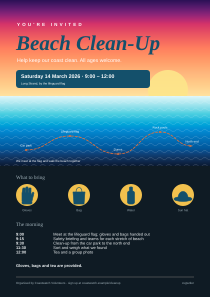

In [6]:
show(poster, **{'theme': 'night'})

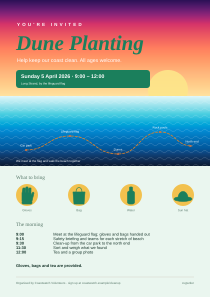

In [7]:
show(poster, **{'theme': 'mint', 'title': 'Dune Planting', 'date': 'Sunday 5 April 2026'})

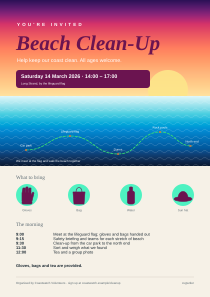

In [8]:
show(poster, **{'hue': 120, 'time': '14:00 – 17:00'})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

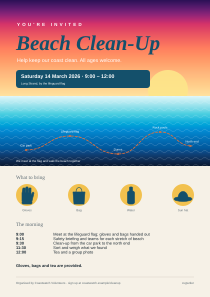

In [9]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))